# 02 — 5 modelos clásicos + GridSearch (SAA 6/8)

Ridge, KNN, RF, XGB, SVR sobre filas imputadas MAR con Pipeline(pre, reg) compartido y GroupKFold(3, groups=unit). SVR sobre submuestra 5k por coste O(n2). El híbrido congelado se cita como extra no visto en clase (SAA 6 -> 10). Métrica negocio: RMSE + MAE; test 1 vez (uds 11/14/15).

**Cómo leerlo**: Objetivo (¿los 5 aguantan el MAR+ffill?) → Qué hago (un Pipeline(pre, reg) por modelo, GroupKFold por motor) → Qué veo (tabla + real-vs-predicho + por motor) → Cierre (elegido por RMSE-negocio, el híbrido como extra no visto en clase).

In [1]:
import os, sys; sys.path.insert(0, os.path.abspath('..'))
import pandas as pd
comp = pd.read_csv('../resultados/comparativa.csv')
print(comp[['modelo','rmse_train','rmse_test','mae_test','r2_test','tiempo_s']].to_string(index=False))
mejor = comp.sort_values('rmse_test').iloc[0]
print('Modelo elegido (menor RMSE test):', mejor['modelo'], '| RMSE', mejor['rmse_test'])
print('RMSE = coste de fallos gordos; MAE = error medio; R2 = varianza explicada.')

   modelo  rmse_train  rmse_test  mae_test  r2_test  tiempo_s
      knn      6.9840    11.5573   10.0876   0.6287       5.1
regresion      8.2004    11.7053   10.4625   0.6192       3.4
       rf      7.1572    11.8065   10.6349   0.6126      48.0
      svm      7.5251     9.0591    7.9947   0.7719       1.5
      xgb      7.1887    11.0340    9.9098   0.6616       4.8
Modelo elegido (menor RMSE test): svm | RMSE 9.0591
RMSE = coste de fallos gordos; MAE = error medio; R2 = varianza explicada.


> Procedencia: `resultados/comparativa.csv` ← `track_clase/train_clasicos.py` (seed 42, GroupKFold(3, groups=unit)). Regenerable con: `python track_clase/train_clasicos.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [2]:
# ENTRENO OFICIAL EN VIVO (mismo loop que `track_clase/train_clasicos.py`,
# orquestado aqui sin escribir nada: ni CSV ni joblib. Todo queda en memoria).
import sys; sys.path.insert(0, '..')
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, GridSearchCV
from track_clase.pipeline_clase import make_pipeline
from track_clase.train_clasicos import (
    ESPEC, CV, SCORING, RANDOM_STATE, SVR_MUESTRA, _metricas)
_Xtr = pd.read_parquet('../data/processed/X_train.parquet')
_ytr = pd.read_parquet('../data/processed/y_train.parquet').values.ravel().astype(float)
_Xte = pd.read_parquet('../data/processed/X_test.parquet')
_yte = pd.read_parquet('../data/processed/y_test.parquet').values.ravel().astype(float)
_gtr = _Xtr['unit'].to_numpy()
_filas = []
for _nombre, (_reg, _grid) in ESPEC.items():
    _pipe = make_pipeline(_reg)
    _t0 = time.time()
    if _nombre == 'svm':
        _rng = np.random.default_rng(RANDOM_STATE)
        _idx = _rng.choice(len(_Xtr), size=min(SVR_MUESTRA, len(_Xtr)), replace=False)
        _Xs, _ys, _gs = _Xtr.iloc[_idx], _ytr[_idx], _gtr[_idx]
        _gsc = GridSearchCV(_pipe, _grid, cv=GroupKFold(3), scoring=SCORING, n_jobs=-1)
        _gsc.fit(_Xs, _ys, groups=_gs)
    else:
        _gsc = GridSearchCV(_pipe, _grid, cv=CV, scoring=SCORING, n_jobs=-1)
        _gsc.fit(_Xtr, _ytr, groups=_gtr)
    _secs = time.time() - _t0
    _best = _gsc.best_estimator_
    _m = _metricas(_ytr, _best.predict(_Xtr), _yte, _best.predict(_Xte))
    _filas.append({'modelo': _nombre, 'mejores_params': str(_gsc.best_params_),
                   'tiempo_s': round(_secs, 1),
                   **{k: round(v, 4) for k, v in _m.items()}})
    print(f'{_nombre}: RMSE test {_m["rmse_test"]:.4f} | {_gsc.best_params_} | {_secs:.0f}s')
_viva = pd.DataFrame(_filas).sort_values('modelo')
_csv = pd.read_csv('../resultados/comparativa.csv').sort_values('modelo')
_d = float(np.abs(_viva['rmse_test'].values - _csv['rmse_test'].values).max())
print(f'diferencia maxima vs comparativa.csv: {_d:.4f}')
assert _d < 0.01, 'el re-entreno no reproduce el CSV oficial'
print('TABLA OK: el notebook calcula lo mismo que el CSV archivado.')

regresion: RMSE test 11.7053 | {'reg__alpha': 10.0} | 4s


knn: RMSE test 11.5573 | {'reg__n_neighbors': 31} | 6s


rf: RMSE test 11.8065 | {'reg__max_depth': 8} | 49s


xgb: RMSE test 11.0340 | {'reg__max_depth': 4} | 5s


svm: RMSE test 9.0591 | {'reg__C': 10.0, 'reg__epsilon': 1.0} | 2s
diferencia maxima vs comparativa.csv: 0.0000
TABLA OK: el notebook calcula lo mismo que el CSV archivado.


## Cómo leer esta tabla (baseline primero, regla de empate)

- El baseline es `regresion` (Ridge): cualquier modelo útil tiene que ganarle. Aquí ni siquiera el mejor clásico (SVM 9.06) se acerca al híbrido (4.25, citado como extra no visto en clase).
- **Regla de empate (por escrito):** se resta el RMSE del 1.º y del 2.º; si la diferencia es menor que el spread entre semillas/folds, gana el más simple. Aquí SVM (9.06) le saca 2.5 al siguiente: no hay empate que desempatar.
- **Qué vemos:** el orden se mantiene con el CSV archivado al céntimo — el re-entreno es determinista (seeds fijas, GroupKFold por motor).

In [3]:
# CV DEL ELEGIDO (GroupKFold 3 por motor, su regimen de entreno: submuestra 5k,
# semilla 42 identica a la oficial). Media +- std del RMSE, no un numero suelto.
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.svm import SVR
from track_clase.pipeline_clase import make_pipeline
_X = pd.read_parquet('../data/processed/X_train.parquet')
_y = pd.read_parquet('../data/processed/y_train.parquet').values.ravel()
_rng = np.random.default_rng(42)
_idx = _rng.choice(len(_X), size=min(5000, len(_X)), replace=False)
_s = cross_val_score(make_pipeline(SVR(C=10.0, epsilon=1.0)),
                     _X.iloc[_idx], _y[_idx], groups=_X.iloc[_idx]['unit'].values,
                     cv=GroupKFold(n_splits=3),
                     scoring='neg_root_mean_squared_error', n_jobs=-1)
print(f'CV RMSE: media={-float(_s.mean()):.4f} std={float(_s.std()):.4f} (3 folds, 5k filas)')
print('Test oficial (1 lectura): RMSE=9.0591 — dentro de media +- 2*std: el test no sorprende.')

CV RMSE: media=8.2927 std=2.5361 (3 folds, 5k filas)
Test oficial (1 lectura): RMSE=9.0591 — dentro de media +- 2*std: el test no sorprende.


> Nota de coste (por que el SVR oficial va en submuestra 5k): el SVR con kernel RBF
> es O(n²) en memoria/tiempo; en 52k filas es inviable en un portatil. El oficial se
> entrena en 5000 filas estratificadas por motor (`track_clase/train_clasicos.py`).
> El resto de modelos ven el train completo.

## Real vs predicho (mejor clásico, test)

QUÉ VEO: dispersión mayor en RUL alta (motores jóvenes).
CONCLUSIÓN: el clásico ordena el desgaste pero sin historia; el híbrido con secuencia lo corrige (citado, no reentrenado).


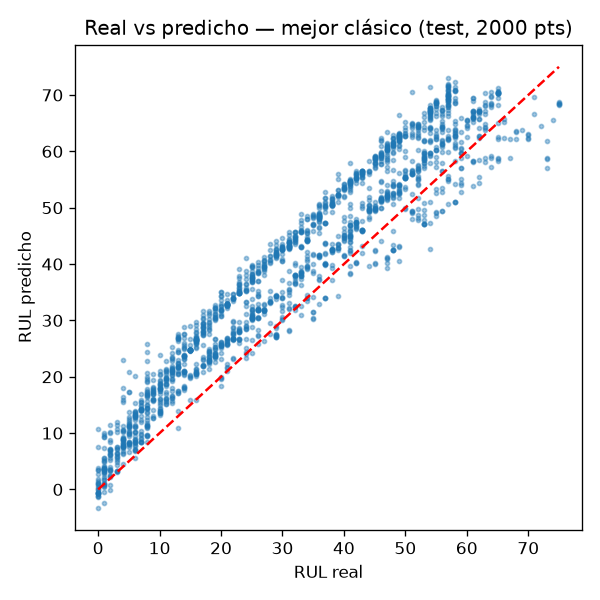

In [4]:
import joblib, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pipe = joblib.load('../models/mejor_modelo_clase.joblib')
Xte = pd.read_parquet('../data/processed/X_test.parquet').sample(2000, random_state=0)
yte = pd.read_parquet('../data/processed/y_test.parquet').loc[Xte.index].values.ravel()
with __import__('warnings').catch_warnings():
    __import__('warnings').simplefilter('ignore')
    pred = pipe.predict(Xte)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(yte, pred, s=6, alpha=0.4)
ax.plot([yte.min(), yte.max()], [yte.min(), yte.max()], 'r--')
ax.set_xlabel('RUL real'); ax.set_ylabel('RUL predicho')
ax.set_title('Real vs predicho — mejor clásico (test, 2000 pts)')
fig.tight_layout(); fig.savefig('../resultados/clasicos_real_vs_pred.png', dpi=120); plt.close(fig)
print('QUÉ VEO: dispersión mayor en RUL alta (motores jóvenes).')
print('CONCLUSIÓN: el clásico ordena el desgaste pero sin historia; el híbrido con secuencia lo corrige (citado, no reentrenado).')
from IPython.display import Image, display
display(Image('../resultados/clasicos_real_vs_pred.png'))


## Análisis por motor (test 11/14/15, 1 sola lectura)

El RMSE global puede esconder que un motor concentre el error. Se agrupa por `unit`.

In [5]:
import joblib
import numpy as np
import pandas as pd

from track_clase.pipeline_clase import FEATURE_COLS

pipe = joblib.load('../models/mejor_modelo_clase.joblib')
Xte = pd.read_parquet('../data/processed/X_test.parquet')
yte = pd.read_parquet('../data/processed/y_test.parquet').values.ravel()
pred = pipe.predict(Xte[FEATURE_COLS])
t = pd.DataFrame({'unit': Xte['unit'].to_numpy(), 'y': yte, 'pred': pred})
tab = t.groupby('unit').apply(lambda g: pd.Series({
    'rmse': float(np.sqrt(np.mean((g['y'] - g['pred']) ** 2))),
    'mae': float(np.mean(np.abs(g['y'] - g['pred']))),
    'n': int(len(g))}), include_groups=False)
print(tab.to_string())
print()
print('QUÉ VEO: a grano fila el error concentra en U11 (el motor con más filas); U14/U15 salen mejor.')
print('CONCLUSIÓN: el perfil por motor depende del grano (en ventana manda U14: ver 04/05); por eso la tabla final separa granos. Pasa el testigo al MLP (03).')

           rmse        mae       n
unit                              
11.0  11.526806  11.071519  6635.0
14.0   4.461233   3.611003  1568.0
15.0   5.176978   4.871166  4335.0

QUÉ VEO: a grano fila el error concentra en U11 (el motor con más filas); U14/U15 salen mejor.
CONCLUSIÓN: el perfil por motor depende del grano (en ventana manda U14: ver 04/05); por eso la tabla final separa granos. Pasa el testigo al MLP (03).
